# Evaluation Notebook

This notebook features all evaluations in terms of metrics and visualizations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.optimize import linear_sum_assignment

## Data loading

In [2]:
### Only these three variables need to be changed for evaluation of different experiments ###

n_queries = 40
experiment_name = 'paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166'
df_signals = pd.read_csv("../datagen/data/test/comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166.csv")


In [3]:
# Define parent folder and create target directory for this experiment's plots
plots_parent_dir = 'evaluation_plots'
save_dir = os.path.join(plots_parent_dir, experiment_name)
os.makedirs(save_dir, exist_ok=True)
print(f"Plots will be saved to: {save_dir}")

Plots will be saved to: evaluation_plots\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166


In [4]:
# Load the evaluation data
import glob

# Load test predictions
file_pattern_test = f'./inference_eval/test_predictions_{experiment_name}*.csv'
matching_files_test = glob.glob(file_pattern_test)
if len(matching_files_test) == 0:
    raise FileNotFoundError(f"No test prediction CSV found matching: {file_pattern_test}")
elif len(matching_files_test) > 1:
    print(f"Warning: Multiple test files found. Using: {matching_files_test[0]}")
df = pd.read_csv(matching_files_test[0])
print(f"Loaded test predictions from: {matching_files_test[0]}")

# Load validation predictions (used only for threshold selection)
file_pattern_val = f'./inference_eval/val_predictions_{experiment_name}*.csv'
matching_files_val = glob.glob(file_pattern_val)
if len(matching_files_val) == 0:
    raise FileNotFoundError(f"No validation prediction CSV found matching: {file_pattern_val}. "
                            "Run run_inference.py first.")
elif len(matching_files_val) > 1:
    print(f"Warning: Multiple val files found. Using: {matching_files_val[0]}")
df_val = pd.read_csv(matching_files_val[0])
print(f"Loaded validation predictions from: {matching_files_val[0]}")

df.head()


Loaded test predictions from: ./inference_eval\test_predictions_paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166.csv
Loaded validation predictions from: ./inference_eval\val_predictions_paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166.csv


,MD_comp1,FA_comp1,dir_X_comp1,dir_Y_comp1,dir_Z_comp1,weight_comp1,MD_comp2,FA_comp2,dir_X_comp2,dir_Y_comp2,...,pred_q39_dir_z,pred_q39_w,pred_q39_extnc,pred_q40_md,pred_q40_fa,pred_q40_dir_x,pred_q40_dir_y,pred_q40_dir_z,pred_q40_w,pred_q40_extnc
0,0.883565,0.816366,0.422715,-0.327964,0.844838,0.066764,3.180628,0.477518,0.958173,-0.248248,...,0.154511,0.130829,0.182262,2.949596,0.759784,0.117168,-0.566488,0.815698,0.159589,0.726084
1,2.600306,0.299466,0.291518,-0.725130,-0.623862,0.353241,0.010374,0.288574,0.417617,-0.383421,...,0.689709,0.688147,0.185297,2.046598,0.405838,-0.275362,0.539915,0.795404,0.133160,0.173860
2,3.249993,0.429497,0.281876,-0.371378,-0.884661,0.436653,2.224580,0.608600,0.229775,0.302931,...,0.925603,0.530173,0.186161,2.257787,0.623097,0.189630,0.302249,0.934177,0.640519,0.384008
3,1.332899,0.577587,0.090074,0.755948,0.648405,0.298507,3.026362,0.250764,0.800968,0.395244,...,0.701704,0.190815,0.455680,2.166650,0.575751,0.341700,0.381978,0.858682,0.093623,0.092040
4,3.483688,0.241257,0.525586,0.089139,-0.846058,0.369914,2.290482,0.574805,0.056774,-0.865009,...,0.003445,0.164812,0.053466,3.167778,0.370276,-0.232777,-0.133279,0.963354,0.151547,0.109789


## Metric evaluation

In [5]:
# config
# global max values
md_max = 4.0
fa_max = 1.0
direction_max = 180 # expressed in degrees of deviation

In [6]:
def calculate_nd_assignment(sample, threshold_in_percentage = 0.07, extnc_threshold=0.0):
    """
    Calculates the Normalized Distance (ND) assignment between predictions and ground truth.
    Returns a dictionary mapping GT compartment index to a list of metrics
    [md_diff, fa_diff, dir_diff, w_diff, pred_extnc] for all assigned predictions.
    Also includes an 'unassigned' key containing a list of existence scores for predictions 
    above the threshold that were not assigned to any ground truth.
    """

    # absolute thresholds
    md_threshold = threshold_in_percentage * md_max
    fa_threshold = threshold_in_percentage * fa_max
    direction_threshold = threshold_in_percentage * direction_max # expressed in degrees of deviation

    n_comp_gt = int(sample['n_comp'])
    
    # Extract GT compartments
    gt_comps = {}
    for i in range(1, n_comp_gt + 1):
        gt_md = sample[f'MD_comp{i}']
        gt_fa = sample[f'FA_comp{i}']
        gt_w = sample[f'weight_comp{i}']
        gt_v = np.array([sample[f'dir_X_comp{i}'], sample[f'dir_Y_comp{i}'], sample[f'dir_Z_comp{i}']])
        gt_norm = np.linalg.norm(gt_v)
        if gt_norm > 0:
            gt_v = gt_v / gt_norm
        gt_comps[i] = {'md': gt_md, 'fa': gt_fa, 'dir': gt_v, 'weight': gt_w}
        
    # Extract Pred compartments above threshold
    pred_comps = {}
    for i in range(1, n_queries + 1):
        extnc = sample[f'pred_q{i}_extnc']
        if extnc >= extnc_threshold:
            pred_md = sample[f'pred_q{i}_md']
            pred_fa = sample[f'pred_q{i}_fa']
            pred_w = sample[f'pred_q{i}_w']
            pred_v = np.array([sample[f'pred_q{i}_dir_x'], sample[f'pred_q{i}_dir_y'], sample[f'pred_q{i}_dir_z']])
            pred_norm = np.linalg.norm(pred_v)
            if pred_norm > 0:
                pred_v = pred_v / pred_norm
            pred_comps[i] = {'md': pred_md, 'fa': pred_fa, 'dir': pred_v, 'weight': pred_w, 'extnc': extnc}
            
    # Initialize assignment mapping for all GT compartments and unassigned
    assignment = {i: [] for i in gt_comps.keys()}
    assignment['unassigned'] = []
    
    # Match each valid prediction to the best GT compartment
    for p_idx, p_comp in pred_comps.items():
        best_gt_idx = None
        best_nd_score = float('inf')
        matched_diffs = None
        
        for gt_idx, gt_comp in gt_comps.items():
            md_diff = abs(p_comp['md'] - gt_comp['md'])
            fa_diff = abs(p_comp['fa'] - gt_comp['fa'])
            
            # Calculate angle difference (undirected, so absolute dot product)
            dot = np.dot(p_comp['dir'], gt_comp['dir'])
            dot = np.clip(dot, -1.0, 1.0)
            angle_rad = np.arccos(np.abs(dot))
            dir_diff = np.degrees(angle_rad) # in degrees
            
            # Check if all features are within the defined thresholds
            if md_diff <= md_threshold and fa_diff <= fa_threshold and dir_diff <= direction_threshold:
                # Calculate normalized sum of differences for scoring the match
                nd_score = (md_diff / md_max) + (fa_diff / fa_max) + (dir_diff / direction_max)
                
                if nd_score < best_nd_score:
                    best_nd_score = nd_score
                    best_gt_idx = gt_idx
                    w_diff = abs(p_comp['weight'] - gt_comp['weight'])
                    matched_diffs = [md_diff, fa_diff, dir_diff, w_diff, p_comp['extnc']]
                    
        # Assign prediction to the best matched GT compartment
        if best_gt_idx is not None:
            assignment[best_gt_idx].append(matched_diffs)
        else:
            assignment['unassigned'].append(p_comp['extnc'])
            
    return assignment

# # Test on a sample
# sample_test = df.iloc[500] # Using the same sample as in visualization
# result = calculate_nd_assignment(sample_test, extnc_threshold=0.0)
# print(f"Assignment for sample 500: {result}")

In [7]:
def calculate_map_101(df, extnc_threshold=0.0, nd_threshold=0.07):
    """
    Calculates the mean Average Precision (mAP) score using the 101-point 
    interpolated sampling method (COCO style).
    """
    all_preds = []
    total_gt = 0
    
    # 1. Collect all predictions and ground truths across the dataset
    for idx, row in df.iterrows():
        total_gt += int(row['n_comp'])
        assignment = calculate_nd_assignment(row, threshold_in_percentage=nd_threshold, extnc_threshold=extnc_threshold)
        
        for gt_idx, preds in assignment.items():
            if gt_idx == 'unassigned':
                for extnc in preds:
                    all_preds.append({'confidence': extnc, 'matched_gt_id': None})
            else:
                for p in preds:
                    # p is [md_diff, fa_diff, dir_diff, w_diff, pred_extnc]
                    extnc = p[4]
                    all_preds.append({'confidence': extnc, 'matched_gt_id': f"{idx}_{gt_idx}"})
                    
    # 2. Sort descending by confidence (existence score)
    all_preds.sort(key=lambda x: x['confidence'], reverse=True)
    
    tp = np.zeros(len(all_preds))
    fp = np.zeros(len(all_preds))
    seen_gts = set()
    
    # 3. Determine True Positives and False Positives
    for i, pred in enumerate(all_preds):
        gt_id = pred['matched_gt_id']
        
        if gt_id is not None:
            # If the GT hasn't been matched yet by a higher-confidence prediction
            if gt_id not in seen_gts:
                tp[i] = 1
                seen_gts.add(gt_id)
            else:
                # Multiple predictions assigned to the same GT -> False Positive
                fp[i] = 1 
        else:
            # Unassigned prediction -> False Positive
            fp[i] = 1 
            
    # 4. Cumulative sums to calculate Precision & Recall across the confidence distribution
    acc_tp = np.cumsum(tp)
    acc_fp = np.cumsum(fp)
    
    recalls = acc_tp / total_gt if total_gt > 0 else np.zeros_like(acc_tp)
    precisions = acc_tp / (np.maximum(acc_tp + acc_fp, np.finfo(float).eps))
    
    # 5. 101-point interpolation (COCO standard)
    recall_thresholds = np.linspace(0.0, 1.0, 101)
    interpolated_precisions = []
    
    for r in recall_thresholds:
        # P_interp(r) = max(P(r_tilde)) for r_tilde >= r
        valid_precisions = precisions[recalls >= r]
        if len(valid_precisions) > 0:
            interpolated_precisions.append(np.max(valid_precisions))
        else:
            interpolated_precisions.append(0.0)
            
    mAP = np.mean(interpolated_precisions)
    
    return mAP, precisions, recalls

# Run the mAP evaluation
# Note: For a holistic PR curve, it's standard to run this with an extnc_threshold of 0.0 or a very low number
my_threshold = 0.00001
mAP_sum = 0.0
mAP_list = []
for nd_threshold in [0.05, 0.07, 0.1]:
    mAP_score, precisions, recalls = calculate_map_101(df, extnc_threshold=my_threshold, nd_threshold=nd_threshold)
    print(f"mAP (101-point) over the dataset at nd threshold {nd_threshold}: {mAP_score:.4f}")
    mAP_sum += mAP_score
    mAP_list.append(mAP_score)

average_mAP = mAP_sum / 3
print(f"Average mAP (101-point) over the dataset across nd thresholds: {average_mAP:.4f}")

mAP (101-point) over the dataset at nd threshold 0.05: 0.0829
mAP (101-point) over the dataset at nd threshold 0.07: 0.1550
mAP (101-point) over the dataset at nd threshold 0.1: 0.2707
Average mAP (101-point) over the dataset across nd thresholds: 0.1695


Saved PR curves plot to: evaluation_plots\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166_pr_curves_map101.pdf


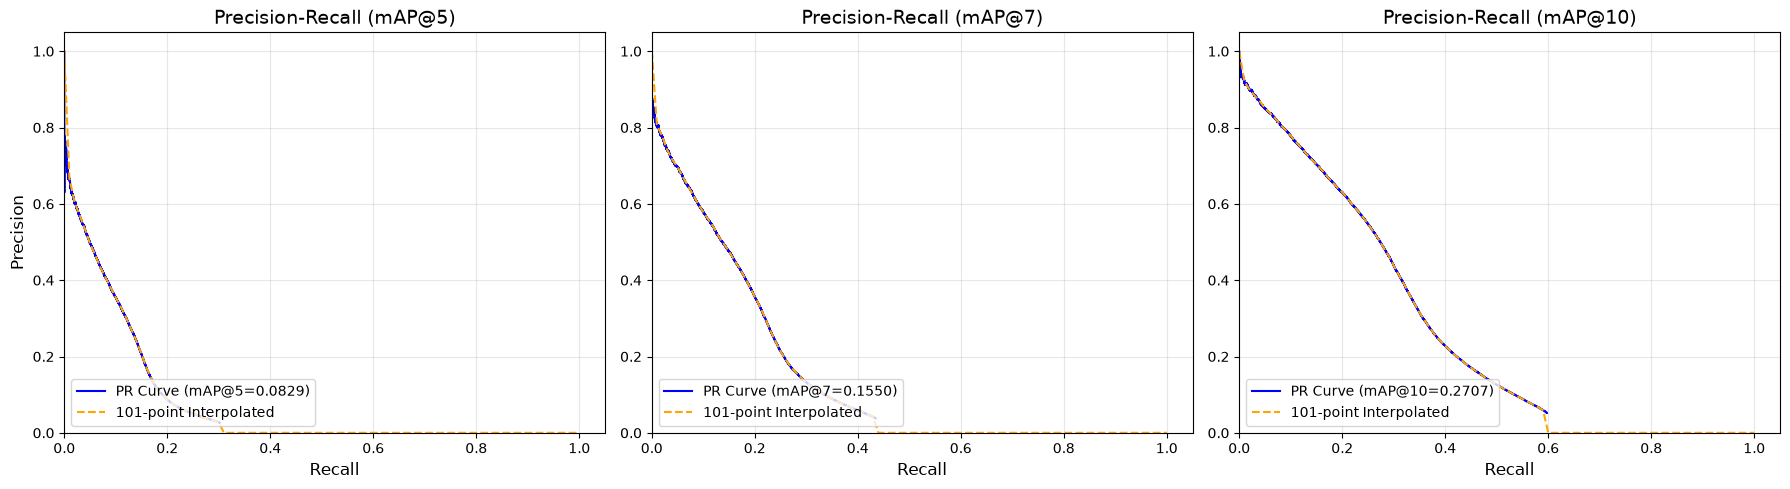

In [8]:
# Plot PR curve and Interpolated PR curve for all evaluated nd_thresholds

nd_thresholds = [0.05, 0.07, 0.1]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, nd_thresh in enumerate(nd_thresholds):
    mAP_score, precisions, recalls = calculate_map_101(df, extnc_threshold=my_threshold, nd_threshold=nd_thresh)
    
    ax = axes[i]
    
    # Plot raw PR curve (Solid blue)
    thresh_val = int(nd_thresh * 100)
    ax.plot(recalls, precisions, label=f'PR Curve (mAP@{thresh_val}={mAP_score:.4f})', color='blue', linewidth=1.5)

    # Calculate 101-point interpolated precisions for the visualization
    recall_thresholds = np.linspace(0.0, 1.0, 101)
    interpolated_precisions = []
    for r in recall_thresholds:
        valid_precisions = precisions[recalls >= r]
        if len(valid_precisions) > 0:
            interpolated_precisions.append(np.max(valid_precisions))
        else:
            interpolated_precisions.append(0.0)

    # Plot interpolated PR curve (Dashed orange)
    ax.plot(recall_thresholds, interpolated_precisions, label='101-point Interpolated', color='orange', linestyle='--')

    ax.set_title(f'Precision-Recall (mAP@{thresh_val})', fontsize=14)
    ax.set_xlabel('Recall', fontsize=12)
    if i == 0:
        ax.set_ylabel('Precision', fontsize=12)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend(loc='lower left')

plt.tight_layout()

# Save the plot
pr_curve_path = os.path.join(save_dir, f"{experiment_name}_pr_curves_map101.pdf")
plt.savefig(pr_curve_path, format='pdf', bbox_inches='tight', dpi=300)
print(f"Saved PR curves plot to: {pr_curve_path}")

plt.show()

In [9]:
def calculate_exact_metrics(df, extnc_threshold=0.5):
    """
    Calculates Precision, Recall, and F1-Score across the dataset 
    at a specific existence threshold based on the ND matching logic.
    """
    TP = 0
    FP = 0
    FN = 0
    total_md_diff = 0.0
    total_fa_diff = 0.0
    total_dir_diff = 0.0
    total_w_diff = 0.0
    total_preds = 0
    
    for idx, row in df.iterrows():
        assignment = calculate_nd_assignment(row, extnc_threshold=extnc_threshold)
        
        for gt_idx, preds in assignment.items():
            if gt_idx == 'unassigned':
                # All unassigned predictions are False Positives
                FP += len(preds)
                total_preds += len(preds)
            else:
                total_preds += len(preds)
                if len(preds) > 0:
                    # Sort by confidence to get the highest confidence True Positive match
                    preds.sort(key=lambda x: x[4], reverse=True)
                    # One prediction successfully matches the GT (True Positive)
                    TP += 1
                    total_md_diff += preds[0][0] # md_diff is at index 0
                    total_fa_diff += preds[0][1] # fa_diff is at index 1
                    total_dir_diff += preds[0][2] # dir_diff is at index 2
                    total_w_diff += preds[0][3] # w_diff is at index 3
                    # Any extra predictions pointing to the same GT are False Positives
                    FP += (len(preds) - 1)
                else:
                    # GT has no assigned predictions -> False Negative
                    FN += 1
                    
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    avg_md_diff = total_md_diff / TP if TP > 0 else 0.0
    avg_fa_diff = total_fa_diff / TP if TP > 0 else 0.0
    avg_dir_diff = total_dir_diff / TP if TP > 0 else 0.0
    avg_w_diff = total_w_diff / TP if TP > 0 else 0.0
    avg_pred_comp = total_preds / len(df) if len(df) > 0 else 0.0
    
    return {
        'threshold': extnc_threshold,
        'TP': TP,
        'FP': FP,
        'FN': FN,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'Avg MD Diff': avg_md_diff,
        'Avg FA Diff': avg_fa_diff,
        'Avg Angle Diff': avg_dir_diff,
        'Avg Weight Diff': avg_w_diff,
        'Avg Pred Comp': avg_pred_comp
    }

# Find the best F1 score threshold on the VALIDATION set (0.25–0.75 in steps of 0.05).
# The threshold is then applied to the test set to avoid optimistic bias.
best_f1 = -1.0
best_metrics = None
best_threshold = None

for thresh in np.arange(0.25, 0.76, 0.05):
    # Round to avoid floating point precision issues (e.g. 0.60000000001)
    thresh = round(thresh, 2)
    current_metrics = calculate_exact_metrics(df_val, extnc_threshold=thresh)
    if current_metrics['F1 Score'] > best_f1:
        best_f1 = current_metrics['F1 Score']
        best_metrics = current_metrics
        best_threshold = thresh

# Use the best metrics moving forward
metrics = best_metrics

print(f"--- Best Hard Threshold Metrics (extnc >= {metrics['threshold']:.2f}) ---")
print(f"True Positives (TP) : {metrics['TP']}")
print(f"FP (total unassigned/excess preds) : {metrics['FP']}")
print(f"FN (missed ground truth comps)   : {metrics['FN']}")
print(f"Precision           : {metrics['Precision']:.4f}")
print(f"Recall              : {metrics['Recall']:.4f}")
print(f"F1 Score            : {metrics['F1 Score']:.4f}")
print(f"Avg MD Diff         : {metrics['Avg MD Diff']:.4f}")
print(f"Avg FA Diff         : {metrics['Avg FA Diff']:.4f}")
print(f"Avg Angle Diff      : {metrics['Avg Angle Diff']:.4f}")
print(f"Avg Weight Diff     : {metrics['Avg Weight Diff']:.4f}")
print(f"Avg Pred Comps      : {metrics['Avg Pred Comp']:.4f}")

--- Best Hard Threshold Metrics (extnc >= 0.35) ---
True Positives (TP) : 18770
FP (total unassigned/excess preds) : 40469
FN (missed ground truth comps)   : 68730
Precision           : 0.3169
Recall              : 0.2145
F1 Score            : 0.2558
Avg MD Diff         : 0.1042
Avg FA Diff         : 0.0282
Avg Angle Diff      : 3.2631
Avg Weight Diff     : 0.0659
Avg Pred Comps      : 2.3696


## Visual evaluation

Spectra visualization

In [10]:
def visualize_sample(df, sample_idx, extnc_threshold=0.0, save_path=None):
    sample = df.iloc[sample_idx]
    n_comp = int(sample['n_comp'])
    
    # Collect Ground Truth
    gt_mds, gt_fas, gt_weights, gt_colors = [], [], [], []
    for i in range(1, n_comp + 1):
        gt_mds.append(sample[f'MD_comp{i}'])
        fa = sample[f'FA_comp{i}']
        gt_fas.append(fa)
        gt_weights.append(sample[f'weight_comp{i}'] * 1000)
        
        dx, dy, dz = sample[f'dir_X_comp{i}'], sample[f'dir_Y_comp{i}'], sample[f'dir_Z_comp{i}']
        norm = np.sqrt(dx**2 + dy**2 + dz**2)
        if norm > 0:
            gt_colors.append((np.abs(dx/norm) * fa, np.abs(dy/norm) * fa, np.abs(dz/norm) * fa))
        else:
            gt_colors.append((0, 0, 0))
            
    # Collect Predictions
    pred_mds, pred_fas, pred_weights, pred_colors = [], [], [], []

    for i in range(1, n_queries + 1):
        extnc = sample[f'pred_q{i}_extnc']
        if extnc >= extnc_threshold:
            pred_mds.append(sample[f'pred_q{i}_md'])
            fa = sample[f'pred_q{i}_fa']
            pred_fas.append(fa)
            pred_weights.append(sample[f'pred_q{i}_w'] * 1000)
            
            dx, dy, dz = sample[f'pred_q{i}_dir_x'], sample[f'pred_q{i}_dir_y'], sample[f'pred_q{i}_dir_z']
            norm = np.sqrt(dx**2 + dy**2 + dz**2)
            if norm > 0:
                pred_colors.append((np.abs(dx/norm) * fa, np.abs(dy/norm) * fa, np.abs(dz/norm) * fa))
            else:
                pred_colors.append((0, 0, 0))
                
    # Plotting
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # 1. Ground Truth
    axes[0].scatter(gt_mds, gt_fas, s=gt_weights, c=gt_colors, alpha=0.9, edgecolors='k')
    axes[0].set_title(f'Ground Truth (Sample {sample_idx})')
    axes[0].set_xlabel(r'Mean Diffusivity (MD) [$10^{-3} \, \mathrm{mm}^2/\mathrm{s}$]')
    axes[0].set_ylabel('Fractional Anisotropy (FA)')
    axes[0].set_xlim(0, 4)
    axes[0].set_ylim(0, 1.0)
    axes[0].grid(alpha=0.3)
    
    # 2. Predictions
    axes[1].scatter(pred_mds, pred_fas, s=pred_weights, c=pred_colors, alpha=0.9, edgecolors='k')
    axes[1].set_title(f'Predictions (extnc threshold: {extnc_threshold})')
    axes[1].set_xlabel(r'Mean Diffusivity (MD) [$10^{-3} \, \mathrm{mm}^2/\mathrm{s}$]')
    axes[1].set_ylabel('Fractional Anisotropy (FA)')
    axes[1].set_xlim(0, 4)
    axes[1].set_ylim(0, 1.0)
    axes[1].grid(alpha=0.3)
    
    # 3. Combined
    axes[2].scatter(gt_mds, gt_fas, s=gt_weights, c=gt_colors, alpha=0.3, edgecolors='black', linewidths=2, linestyle='--')
    axes[2].scatter(pred_mds, pred_fas, s=pred_weights, c=pred_colors, alpha=0.9, edgecolors='k')

    axes[2].set_title('Combined View')
    axes[2].set_xlabel(r'Mean Diffusivity (MD) [$10^{-3} \, \mathrm{mm}^2/\mathrm{s}$]')
    axes[2].set_ylabel('Fractional Anisotropy (FA)')
    axes[2].set_xlim(0, 4)
    axes[2].set_ylim(0, 1.0)
    axes[2].grid(alpha=0.3)
    
    # Custom legend
    gt_legend = axes[2].scatter([], [], s=100, c='gray', alpha=0.3, edgecolors='black', linewidths=2, label='Ground Truth')
    pred_legend = axes[2].scatter([], [], s=100, c='gray', alpha=0.9, edgecolors='k', label='Prediction')
    axes[2].legend(handles=[gt_legend, pred_legend], loc='lower right')
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight', dpi=300)
        print(f"Saved plot to: {save_path}")
    plt.show()

In [11]:
def visualize_sample_without_combined(df, sample_idx, extnc_threshold=0.0, save_path=None):
    sample = df.iloc[sample_idx]
    n_comp = int(sample['n_comp'])
    
    # Collect Ground Truth
    gt_mds, gt_fas, gt_weights, gt_colors = [], [], [], []
    for i in range(1, n_comp + 1):
        gt_mds.append(sample[f'MD_comp{i}'])
        fa = sample[f'FA_comp{i}']
        gt_fas.append(fa)
        gt_weights.append(sample[f'weight_comp{i}'] * 1000)
        
        dx, dy, dz = sample[f'dir_X_comp{i}'], sample[f'dir_Y_comp{i}'], sample[f'dir_Z_comp{i}']
        norm = np.sqrt(dx**2 + dy**2 + dz**2)
        if norm > 0:
            gt_colors.append((np.abs(dx/norm) * fa, np.abs(dy/norm) * fa, np.abs(dz/norm) * fa))
        else:
            gt_colors.append((0, 0, 0))
            
    # Collect Predictions
    pred_mds, pred_fas, pred_weights, pred_colors = [], [], [], []

    for i in range(1, n_queries + 1):
        extnc = sample[f'pred_q{i}_extnc']
        if extnc >= extnc_threshold:
            pred_mds.append(sample[f'pred_q{i}_md'])
            fa = sample[f'pred_q{i}_fa']
            pred_fas.append(fa)
            pred_weights.append(sample[f'pred_q{i}_w'] * 1000)
            
            dx, dy, dz = sample[f'pred_q{i}_dir_x'], sample[f'pred_q{i}_dir_y'], sample[f'pred_q{i}_dir_z']
            norm = np.sqrt(dx**2 + dy**2 + dz**2)
            if norm > 0:
                pred_colors.append((np.abs(dx/norm) * fa, np.abs(dy/norm) * fa, np.abs(dz/norm) * fa))
            else:
                pred_colors.append((0, 0, 0))
                
    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    # 1. Ground Truth
    axes[0].scatter(gt_mds, gt_fas, s=gt_weights, c=gt_colors, alpha=0.9, edgecolors='k')
    axes[0].set_title(f'Ground Truth (Sample {sample_idx})')
    axes[0].set_xlabel(r'Mean Diffusivity (MD) [$10^{-3} \, \mathrm{mm}^2/\mathrm{s}$]')
    axes[0].set_ylabel('Fractional Anisotropy (FA)')
    axes[0].set_xlim(0, 4)
    axes[0].set_ylim(0, 1.0)
    axes[0].grid(alpha=0.3)
    
    # 2. Predictions
    axes[1].scatter(pred_mds, pred_fas, s=pred_weights, c=pred_colors, alpha=0.9, edgecolors='k')
    axes[1].set_title(f'Predictions (extnc threshold: {extnc_threshold})')
    axes[1].set_xlabel(r'Mean Diffusivity (MD) [$10^{-3} \, \mathrm{mm}^2/\mathrm{s}$]')
    axes[1].set_ylabel('Fractional Anisotropy (FA)')
    axes[1].set_xlim(0, 4)
    axes[1].set_ylim(0, 1.0)
    axes[1].grid(alpha=0.3)
    
    
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, format='eps', dpi=300)
        print(f"Saved plot to: {save_path}")
    plt.show()

Saved plot to: evaluation_plots\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166_sample_100_evaluation.pdf


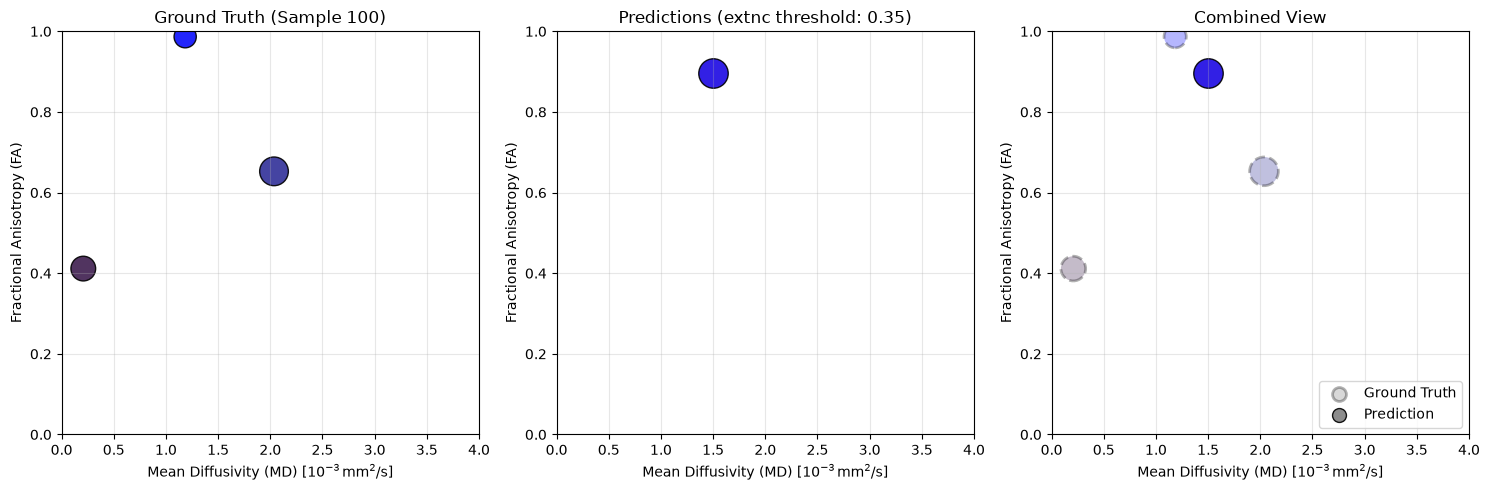

In [12]:
sample_idx = 100
visualize_sample(
    df, 
    sample_idx=sample_idx, 
    extnc_threshold=best_threshold, 
    save_path=os.path.join(save_dir, f"{experiment_name}_sample_{sample_idx}_evaluation.pdf") 
)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved plot to: evaluation_plots\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166_sample_100_evaluation.pdf


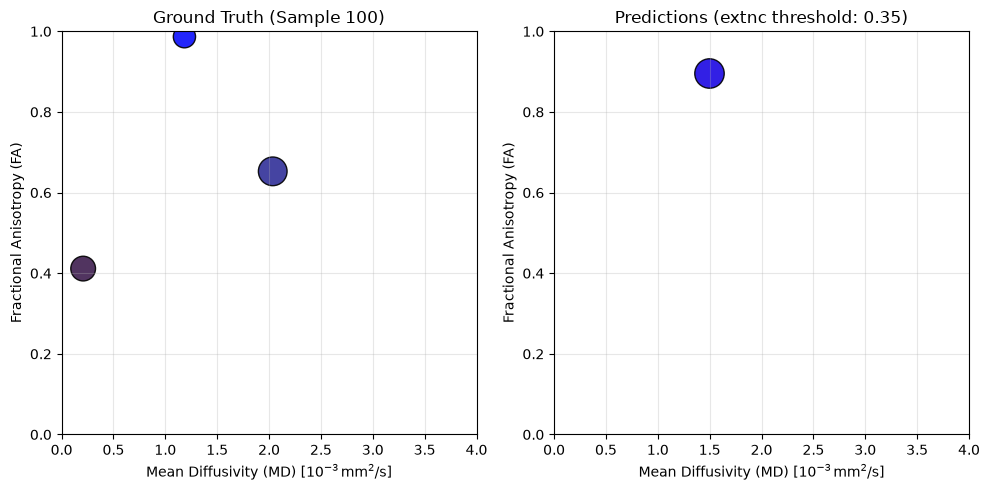

In [13]:
sample_idx = 100
visualize_sample_without_combined(
    df, 
    sample_idx=sample_idx, 
    extnc_threshold=best_threshold, 
    save_path=os.path.join(save_dir, f"{experiment_name}_sample_{sample_idx}_evaluation.pdf") 
)

In [14]:
import os
import matplotlib.pyplot as plt
import numpy as np

def visualize_signal_and_ground_truth_split(df, df_signals, sample_idx, save_path=None):

    # Load diffusion protocol to get b-values
    diff_protocol = np.loadtxt("../datagen/diffusion_protocols/diff_dirs_166.txt", delimiter=',')
    b_values = diff_protocol[:, 0]

    # ==========================================
    # FIGURE 1: Sample MRI Signal
    # ==========================================
    fig1, ax1 = plt.subplots(figsize=(5, 5))

    # Load MRI signal data
    signal_cols = [col for col in df_signals.columns if col.startswith('mri_sig')]
    signal_data = df_signals[signal_cols].iloc[sample_idx].values

    ax1.plot(range(len(signal_data)), signal_data, marker='o', markersize=3, linewidth=1)
    ax1.set_title(f'Example Signal (Sample {sample_idx})')
    ax1.set_ylabel('Signal Value')
    ax1.grid(alpha=0.3)

    # Add alternating background colors for b-values and set xticks
    _, idx = np.unique(b_values, return_index=True)
    unique_b_values_ordered = b_values[np.sort(idx)]

    colors_bg = ['lightgray', 'lightblue']
    xticks = []
    xticklabels = []

    for i, b in enumerate(unique_b_values_ordered):
        indices = np.where(b_values == b)[0]
        start_idx = indices[0] - 0.5
        end_idx = indices[-1] + 0.5
        ax1.axvspan(start_idx, end_idx, facecolor=colors_bg[i % 2], alpha=0.5, zorder=0, linewidth=0, rasterized=True)
        
        # Use the middle of the block for the x-tick label
        xticks.append(np.mean(indices))
        xticklabels.append(str(int(b)))

    ax1.set_xticks(xticks)
    ax1.set_xticklabels(xticklabels)
    
    # UPDATED: Added LaTeX unit for b-value (s/mm^2)
    ax1.set_xlabel(r'b-value ($\mathrm{s/mm}^2$)')
    
    plt.tight_layout()
    
    if save_path:
        # Split extension to append a suffix safely
        base, ext = os.path.splitext(save_path)
        fig1.savefig(f"{base}_signal{ext}", dpi=300)
    
    plt.show()

    # ==========================================
    # FIGURE 2: MD-FA Spectrogram
    # ==========================================
    fig2, ax2 = plt.subplots(figsize=(5, 5))

    # Collect Ground Truth
    sample = df.iloc[sample_idx]
    n_comp = int(sample['n_comp'])
    
    gt_mds, gt_fas, gt_weights, gt_colors = [], [], [], []
    for i in range(1, n_comp + 1):
        gt_mds.append(sample[f'MD_comp{i}'])
        fa = sample[f'FA_comp{i}']
        gt_fas.append(fa)
        gt_weights.append(sample[f'weight_comp{i}'] * 1000)
        
        dx, dy, dz = sample[f'dir_X_comp{i}'], sample[f'dir_Y_comp{i}'], sample[f'dir_Z_comp{i}']
        norm = np.sqrt(dx**2 + dy**2 + dz**2)
        if norm > 0:
            gt_colors.append((np.abs(dx/norm) * fa, np.abs(dy/norm) * fa, np.abs(dz/norm) * fa))
        else:
            gt_colors.append((0, 0, 0))
                
    # Ground Truth Plot
    ax2.scatter(gt_mds, gt_fas, s=gt_weights, c=gt_colors, alpha=0.9, edgecolors='k')
    ax2.set_title(f'Ground Truth (Sample {sample_idx})')
    
    # UPDATED: Added LaTeX unit for MD (10^-3 mm^2/s)
    ax2.set_xlabel(r'Mean Diffusivity (MD) [$10^{-3} \, \mathrm{mm}^2/\mathrm{s}$]')
    ax2.set_ylabel('Fractional Anisotropy (FA)')
    ax2.set_xlim(0, 4)
    ax2.set_ylim(0, 1.05)
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    
    if save_path:
        base, ext = os.path.splitext(save_path)
        fig2.savefig(f"{base}_gt{ext}", dpi=300)

    plt.show()

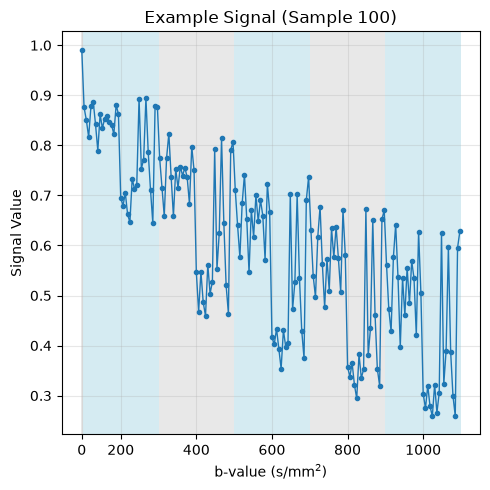

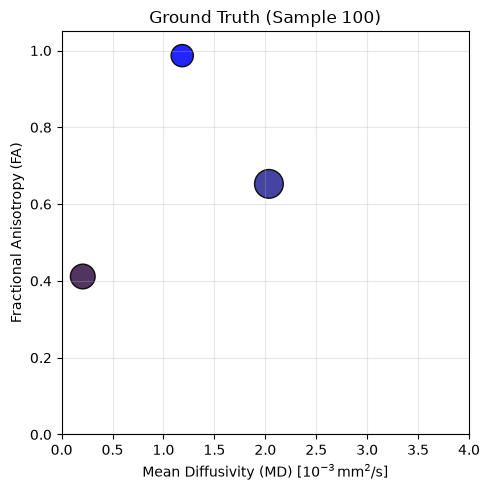

In [15]:
sample_idx = 100
visualize_signal_and_ground_truth_split(
        df, 
        df_signals, 
        sample_idx=sample_idx, 
        save_path=os.path.join(save_dir, f"sample_{sample_idx}_signal_and_ground_truth.pdf") 
    )

Scatter plots

In [36]:
# ── Hungarian matching for scatter plots ──────────────────────────────────────

def _hungarian_match_sample(sample, n_queries, n_comp,
                            md_w=7.5, fa_w=20.0, dir_w=10.0, wt_w=0.4, exs_w=0.7):
    """
    Reproduce the HungarianLoss cost matrix for a single sample (numpy only).
    Returns (row_idx, col_idx): 0-based query and GT compartment indices.
    """
    gt = np.array([
        [sample[f'MD_comp{j}'], sample[f'FA_comp{j}'],
         sample[f'dir_X_comp{j}'], sample[f'dir_Y_comp{j}'], sample[f'dir_Z_comp{j}'],
         sample[f'weight_comp{j}']]
        for j in range(1, n_comp + 1)
    ], dtype=np.float32)  # (n_comp, 6)

    pred = np.array([
        [sample[f'pred_q{i}_md'], sample[f'pred_q{i}_fa'],
         sample[f'pred_q{i}_dir_x'], sample[f'pred_q{i}_dir_y'], sample[f'pred_q{i}_dir_z'],
         sample[f'pred_q{i}_w'], sample[f'pred_q{i}_extnc']]
        for i in range(1, n_queries + 1)
    ], dtype=np.float32)  # (NQ, 7)

    md_cost = (pred[:, 0:1] - gt[np.newaxis, :, 0]) ** 2
    fa_cost = (pred[:, 1:2] - gt[np.newaxis, :, 1]) ** 2
    wt_cost = (pred[:, 5:6] - gt[np.newaxis, :, 5]) ** 2

    pred_dir = pred[:, 2:5]
    gt_dir = gt[:, 2:5]
    pred_n = pred_dir / (np.linalg.norm(pred_dir, axis=1, keepdims=True) + 1e-8)
    gt_n = gt_dir / (np.linalg.norm(gt_dir, axis=1, keepdims=True) + 1e-8)
    cos_sim = np.clip(pred_n @ gt_n.T, -1.0, 1.0)
    dir_cost = (1 - cos_sim) * gt[np.newaxis, :, 1]  # FA-weighted

    cost = (md_w * md_cost + fa_w * fa_cost + dir_w * dir_cost) * gt[np.newaxis, :, 5]
    cost += wt_w * wt_cost
    extnc_scores = pred[:, 6]
    cost += exs_w * (1 - extnc_scores)[:, np.newaxis]

    return linear_sum_assignment(cost)  # row=query (0-based), col=GT (0-based)


def build_matched_arrays(df, n_queries):
    """
    Hungarian-match every sample and return aligned arrays.

    Returns
    -------
    pred_matched : (N, nc_max, 7)  predictions in GT compartment order
    ref          : (N, nc_max, 6)  ground truth
    n_comp       : (N,) int
    """
    nc_max = max(int(row['n_comp']) for _, row in df.iterrows())
    N = len(df)
    pred_matched = np.full((N, nc_max, 7), np.nan, dtype=np.float32)
    ref = np.zeros((N, nc_max, 6), dtype=np.float32)
    n_comp_arr = np.zeros(N, dtype=int)

    for i, (_, row) in enumerate(df.iterrows()):
        nc = int(row['n_comp'])
        n_comp_arr[i] = nc
        for j in range(nc):
            ref[i, j] = [row[f'MD_comp{j + 1}'], row[f'FA_comp{j + 1}'],
                         row[f'dir_X_comp{j + 1}'], row[f'dir_Y_comp{j + 1}'],
                         row[f'dir_Z_comp{j + 1}'], row[f'weight_comp{j + 1}']]

        row_idx, col_idx = _hungarian_match_sample(row, n_queries, nc)
        for r, c in zip(row_idx, col_idx):
            pred_matched[i, c] = [row[f'pred_q{r + 1}_md'], row[f'pred_q{r + 1}_fa'],
                                  row[f'pred_q{r + 1}_dir_x'], row[f'pred_q{r + 1}_dir_y'],
                                  row[f'pred_q{r + 1}_dir_z'], row[f'pred_q{r + 1}_w'],
                                  row[f'pred_q{r + 1}_extnc']]

    return pred_matched, ref, n_comp_arr



# ── scatter / angular plots ───────────────────────────────────────────────────

def _r2(true, pred):
    ss_res = np.sum((pred - true) ** 2)
    ss_tot = np.sum((true - true.mean()) ** 2)
    return 1 - ss_res / ss_tot if ss_tot > 0 else float('nan')


def collect_matched_params(pred_matched, ref, n_comp, param_idx, extnc_threshold=0.0):
    true_vals, pred_vals, fractions = [], [], []
    for i in range(len(n_comp)):
        for j in range(n_comp[i]):
            if np.isnan(pred_matched[i, j, 0]):
                continue
            if pred_matched[i, j, 6] < extnc_threshold:
                continue
            true_vals.append(ref[i, j, param_idx])
            pred_vals.append(pred_matched[i, j, param_idx])
            fractions.append(ref[i, j, 5])
    return np.array(true_vals), np.array(pred_vals), np.array(fractions)


def collect_matched_dirs(pred_matched, ref, n_comp, extnc_threshold=0.0):
    """
    Extract angular errors with both signal fraction and FA for all valid
    matched compartments. Returns (fractions, fas, ang_errors).
    """
    fractions, fas, ang_errors = [], [], []
    for i in range(len(n_comp)):
        for j in range(n_comp[i]):
            if np.isnan(pred_matched[i, j, 0]):
                continue
            if pred_matched[i, j, 6] < extnc_threshold:
                continue
            pdir = pred_matched[i, j, 2:5]
            tdir = ref[i, j, 2:5]
            pn, tn = np.linalg.norm(pdir), np.linalg.norm(tdir)
            if pn < 1e-8 or tn < 1e-8:
                continue
            cos_sim = np.clip(np.dot(pdir / pn, tdir / tn), -1.0, 1.0)
            fractions.append(ref[i, j, 5])
            fas.append(ref[i, j, 1])
            ang_errors.append(np.degrees(np.arccos(abs(cos_sim))))
    return np.array(fractions), np.array(fas), np.array(ang_errors)


def _single_scatter_figure(ax, fig, x, y, c, x_label, y_label, title,
                           norm, cmap, scatter_kw, identity=True, r2=True):
    """Populate a single square scatter axes with optional identity line and R²."""
    ax.scatter(x, y, c=c, **scatter_kw)
    lim_max = np.ceil(max(x.max(), y.max()) * 10.) / 10. if identity else None
    if identity:
        ax.plot([0, lim_max], [0, lim_max], 'k--', linewidth=1.0, label='Identity')
        ax.set_xlim(0, lim_max)
        ax.set_ylim(0, lim_max)
    if r2:
        ax.text(0.03, 0.97, f'$R^2 = {_r2(x, y):.4f}$',
                transform=ax.transAxes, fontsize=10, va='top')
    ax.set_aspect('equal')
    ax.set_box_aspect(1)
    ax.set_xlabel(x_label, fontsize=11)
    ax.set_ylabel(y_label, fontsize=11)
    # ax.set_title(title, fontsize=12)
    ax.tick_params(labelsize=9)
    # ax.grid(True, linestyle='--', alpha=0.3)

    # colorbar anchored to axes height
    fig.canvas.draw()
    pos = ax.get_position()
    cax = fig.add_axes([pos.x1 + 0.02, pos.y0, 0.035, pos.height])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    fig.colorbar(sm, cax=cax)
    cax.set_ylabel('True Signal Fraction', fontsize=10)
    cax.tick_params(labelsize=9)


def _make_scatter_fig():
    """Create a square single-axes figure with consistent size."""
    fig, ax = plt.subplots(figsize=(5.5, 5))
    fig.subplots_adjust(left=0.13, right=0.78, top=0.92, bottom=0.13)
    return fig, ax


def plot_md_scatter(true_mds, pred_mds, fractions_md, save_path=None):
    """True vs predicted MD, coloured by signal fraction."""
    norm = plt.Normalize(vmin=0, vmax=1)
    cmap = plt.get_cmap('plasma')
    scatter_kw = dict(cmap=cmap, norm=norm, s=8, alpha=0.5, rasterized=True)
    fig, ax = _make_scatter_fig()
    _single_scatter_figure(
        ax, fig, true_mds, pred_mds, fractions_md,
        x_label=r'True MD [$10^{-3}$ mm$^2$/s]',
        y_label=r'Predicted MD [$10^{-3}$ mm$^2$/s]',
        title='Mean Diffusivity',
        norm=norm, cmap=cmap, scatter_kw=scatter_kw,
        identity=True, r2=True,
    )
    if save_path:
        plt.savefig(save_path, format='svg', bbox_inches='tight', dpi=300)
        print(f'Saved: {save_path}')
    plt.show()


def plot_fa_scatter(true_fas, pred_fas, fractions_fa, save_path=None):
    """True vs predicted FA, coloured by signal fraction."""
    norm = plt.Normalize(vmin=0, vmax=1)
    cmap = plt.get_cmap('plasma')
    scatter_kw = dict(cmap=cmap, norm=norm, s=8, alpha=0.5, rasterized=True)
    fig, ax = _make_scatter_fig()
    ax.scatter(true_fas, pred_fas, c=fractions_fa, **scatter_kw)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1.0, label='Identity')
    ax.text(0.03, 0.97, f'$R^2 = {_r2(true_fas, pred_fas):.4f}$',
            transform=ax.transAxes, fontsize=10, va='top')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_box_aspect(1)
    ax.set_xlabel('True FA', fontsize=11)
    ax.set_ylabel('Predicted FA', fontsize=11)
    # ax.set_title('Fractional Anisotropy', fontsize=12)
    ax.tick_params(labelsize=9)
    #ax.grid(True, linestyle='--', alpha=0.3)
    fig.canvas.draw()
    pos = ax.get_position()
    cax = fig.add_axes([pos.x1 + 0.02, pos.y0, 0.035, pos.height])
    sm = plt.cm.ScalarMappable(cmap=plt.get_cmap('plasma'), norm=norm)
    sm.set_array([])
    fig.colorbar(sm, cax=cax)
    cax.set_ylabel('Signal Fraction (ground truth)', fontsize=10)
    cax.tick_params(labelsize=9)
    if save_path:
        plt.savefig(save_path, format='svg', bbox_inches='tight', dpi=300)
        print(f'Saved: {save_path}')
    plt.show()


def plot_angular_scatter(fas_ang, fractions_ang, ang_errors, save_path=None):
    """Angular error vs true FA, coloured by signal fraction."""
    norm = plt.Normalize(vmin=0, vmax=1)
    cmap = plt.get_cmap('plasma')
    scatter_kw = dict(cmap=cmap, norm=norm, s=8, alpha=0.5, rasterized=True)
    fig, ax = _make_scatter_fig()
    ax.scatter(fas_ang, ang_errors, c=fractions_ang, **scatter_kw)
    bins = np.linspace(0, 1, 20)
    bin_centers, bin_medians = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (fas_ang >= lo) & (fas_ang < hi)
        if mask.sum() > 0:
            bin_centers.append((lo + hi) / 2)
            bin_medians.append(np.median(ang_errors[mask]))
    ax.plot(bin_centers, bin_medians, 'k-', linewidth=1.5,
            label='Median (binned)', zorder=5)
    print(f'Angular error — Mean: {np.mean(ang_errors):.2f}°  Median: {np.median(ang_errors):.2f}°')
    ax.set_xlim(0, 1)
    ax.set_ylim(bottom=0)
    ax.set_box_aspect(1)
    ax.set_xlabel('True FA', fontsize=11)
    ax.set_ylabel('Angular Error (°)', fontsize=11)
    # ax.set_title('Main Direction Angular Error', fontsize=12)
    ax.tick_params(labelsize=9)
    #ax.grid(True, linestyle='--', alpha=0.3)
    ax.legend(fontsize=9, loc='upper right')
    fig.canvas.draw()
    pos = ax.get_position()
    cax = fig.add_axes([pos.x1 + 0.02, pos.y0, 0.035, pos.height])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    fig.colorbar(sm, cax=cax)
    cax.set_ylabel('True Signal Fraction', fontsize=10)
    cax.tick_params(labelsize=9)
    if save_path:
        plt.savefig(save_path, format='svg', bbox_inches='tight', dpi=300)
        print(f'Saved: {save_path}')
    plt.show()




In [37]:
print(best_threshold)

0.35


Running Hungarian matching...
Saved: evaluation_plots\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166_scatter_md.svg


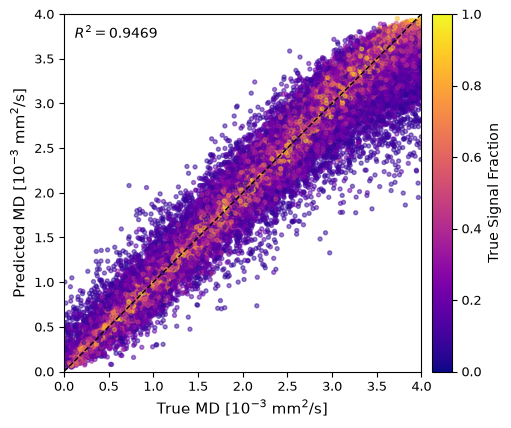

Saved: evaluation_plots\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166_scatter_fa.svg


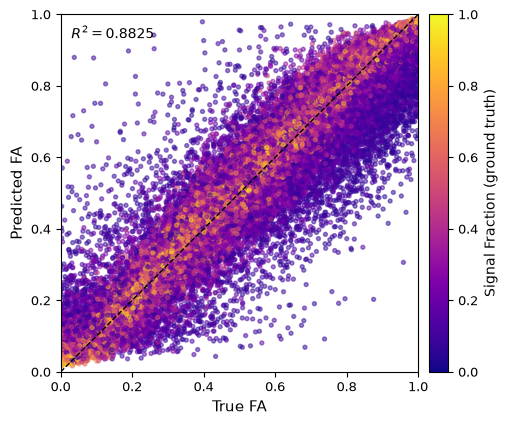

Angular error — Mean: 11.00°  Median: 4.24°
Saved: evaluation_plots\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166_scatter_angular.svg


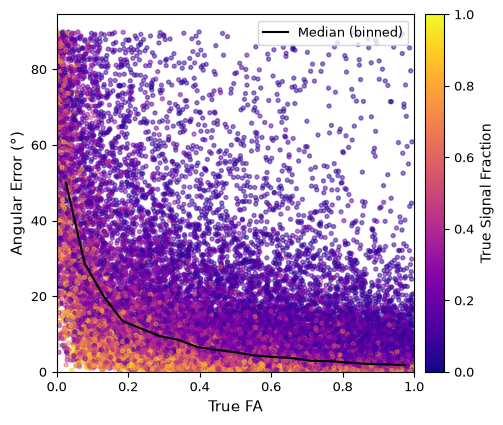

In [38]:
# ── Hungarian matching for scatter / angular plots ────────────────────────
print('Running Hungarian matching...')
pred_matched, ref, n_comp = build_matched_arrays(df, n_queries)


# ── scatter + angular error figures ───────────────────────────────────────
true_mds, pred_mds, fractions_md = collect_matched_params(
    pred_matched, ref, n_comp, param_idx=0, extnc_threshold=best_threshold)
true_fas, pred_fas, fractions_fa = collect_matched_params(
    pred_matched, ref, n_comp, param_idx=1, extnc_threshold=best_threshold)
fractions_ang, fas_ang, ang_errors = collect_matched_dirs(
    pred_matched, ref, n_comp, extnc_threshold=best_threshold)
plot_md_scatter(
    true_mds, pred_mds, fractions_md,
    save_path=os.path.join(save_dir, f'{experiment_name}_scatter_md.svg'))
plot_fa_scatter(
    true_fas, pred_fas, fractions_fa,
    save_path=os.path.join(save_dir, f'{experiment_name}_scatter_fa.svg'))
plot_angular_scatter(
    fas_ang, fractions_ang, ang_errors,
    save_path=os.path.join(save_dir, f'{experiment_name}_scatter_angular.svg'))

Detailed performance analysis (mAP heatmap + mAP grouped by compartment size)

In [19]:
def calculate_map_heatmap(df, extnc_threshold=0.0, nd_threshold=0.07):
    x_min, x_max = 0.0, 4.0
    y_min, y_max = 0.0, 1.0
    nbins_x, nbins_y = 40, 20
    xedges = np.linspace(x_min, x_max, nbins_x + 1)
    yedges = np.linspace(y_min, y_max, nbins_y + 1)
    
    # Store predictions and GT counts per bin
    binned_preds = { (ix, iy): [] for ix in range(nbins_x) for iy in range(nbins_y) }
    binned_gt_counts = { (ix, iy): 0 for ix in range(nbins_x) for iy in range(nbins_y) }
    
    # Absolute thresholds
    md_threshold = nd_threshold * md_max
    fa_threshold = nd_threshold * fa_max
    direction_threshold_val = nd_threshold * direction_max
    
    for idx, row in df.iterrows():
        n_comp_gt = int(row['n_comp'])
        gt_comps = {}
        for i in range(1, n_comp_gt + 1):
            gt_md = row[f'MD_comp{i}']
            gt_fa = row[f'FA_comp{i}']
            gt_w = row[f'weight_comp{i}']
            gt_v = np.array([row[f'dir_X_comp{i}'], row[f'dir_Y_comp{i}'], row[f'dir_Z_comp{i}']])
            gt_norm = np.linalg.norm(gt_v)
            if gt_norm > 0:
                gt_v = gt_v / gt_norm
            gt_comps[i] = {'md': gt_md, 'fa': gt_fa, 'dir': gt_v, 'weight': gt_w}
            
            # Find GT bin
            ix = np.digitize(gt_md, xedges) - 1
            iy = np.digitize(gt_fa, yedges) - 1
            if 0 <= ix < nbins_x and 0 <= iy < nbins_y:
                binned_gt_counts[(ix, iy)] += 1
                
        pred_comps = {}
        for i in range(1, n_queries + 1):
            extnc = row[f'pred_q{i}_extnc']
            if extnc >= extnc_threshold:
                pred_md = row[f'pred_q{i}_md']
                pred_fa = row[f'pred_q{i}_fa']
                pred_w = row[f'pred_q{i}_w']
                pred_v = np.array([row[f'pred_q{i}_dir_x'], row[f'pred_q{i}_dir_y'], row[f'pred_q{i}_dir_z']])
                pred_norm = np.linalg.norm(pred_v)
                if pred_norm > 0:
                    pred_v = pred_v / pred_norm
                pred_comps[i] = {'md': pred_md, 'fa': pred_fa, 'dir': pred_v, 'weight': pred_w, 'extnc': extnc}
                
        # Match
        for p_idx, p_comp in pred_comps.items():
            best_gt_idx = None
            best_nd_score = float('inf')
            
            for gt_idx, gt_comp in gt_comps.items():
                md_diff = abs(p_comp['md'] - gt_comp['md'])
                fa_diff = abs(p_comp['fa'] - gt_comp['fa'])
                
                dot = np.dot(p_comp['dir'], gt_comp['dir'])
                dot = np.clip(dot, -1.0, 1.0)
                angle_rad = np.arccos(np.abs(dot))
                dir_diff = np.degrees(angle_rad)
                
                if md_diff <= md_threshold and fa_diff <= fa_threshold and dir_diff <= direction_threshold_val:
                    nd_score = (md_diff / md_max) + (fa_diff / fa_max) + (dir_diff / direction_max)
                    if nd_score < best_nd_score:
                        best_nd_score = nd_score
                        best_gt_idx = gt_idx
                        
            if best_gt_idx is not None:
                # Prediction correctly assigned. Goes to the bin of its matched GT.
                gt_comp = gt_comps[best_gt_idx]
                ix = np.digitize(gt_comp['md'], xedges) - 1
                iy = np.digitize(gt_comp['fa'], yedges) - 1
                if 0 <= ix < nbins_x and 0 <= iy < nbins_y:
                    binned_preds[(ix, iy)].append({'confidence': p_comp['extnc'], 'matched_gt_id': f"{idx}_{best_gt_idx}"})
            else:
                # Unassigned prediction. Goes to the bin of its predicted MD/FA.
                ix = np.digitize(p_comp['md'], xedges) - 1
                iy = np.digitize(p_comp['fa'], yedges) - 1
                if 0 <= ix < nbins_x and 0 <= iy < nbins_y:
                    binned_preds[(ix, iy)].append({'confidence': p_comp['extnc'], 'matched_gt_id': None})
                    
    # Calculate mAP for each bin
    heatmap = np.zeros((nbins_x, nbins_y))
    
    for (ix, iy) in binned_preds.keys():
        total_gt = binned_gt_counts[(ix, iy)]
        preds = binned_preds[(ix, iy)]
        
        if total_gt == 0:
            heatmap[ix, iy] = np.nan
            continue
            
        preds.sort(key=lambda x: x['confidence'], reverse=True)
        tp = np.zeros(len(preds))
        fp = np.zeros(len(preds))
        seen_gts = set()
        
        for i, pred in enumerate(preds):
            gt_id = pred['matched_gt_id']
            if gt_id is not None:
                if gt_id not in seen_gts:
                    tp[i] = 1
                    seen_gts.add(gt_id)
                else:
                    fp[i] = 1
            else:
                fp[i] = 1
                
        acc_tp = np.cumsum(tp)
        acc_fp = np.cumsum(fp)
        
        recalls = acc_tp / total_gt
        precisions = acc_tp / (np.maximum(acc_tp + acc_fp, np.finfo(float).eps))
        
        recall_thresholds = np.linspace(0.0, 1.0, 101)
        interpolated_precisions = []
        for r in recall_thresholds:
            valid_precisions = precisions[recalls >= r]
            if len(valid_precisions) > 0:
                interpolated_precisions.append(np.max(valid_precisions))
            else:
                interpolated_precisions.append(0.0)
                
        heatmap[ix, iy] = np.mean(interpolated_precisions)
        
    return heatmap, xedges, yedges

heatmap_data, xedges, yedges = calculate_map_heatmap(df, extnc_threshold=0.0, nd_threshold=0.1)

Saved mAP heatmap to: evaluation_plots\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166\paper_model_comp_setup_dynamic__max_n_comp_5__min_n_comp_2__noise_0.01__n_signal_values_166_map_heatmap.svg


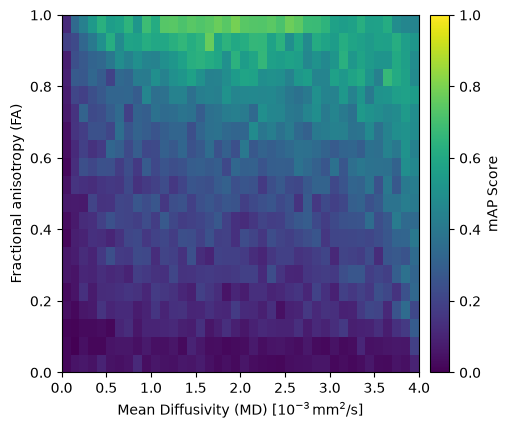

In [39]:
fig, ax = plt.subplots(figsize=(5.5, 5))
fig.subplots_adjust(left=0.13, right=0.78, top=0.92, bottom=0.13)

# Set background to black so that missing values (NaN) appear black
ax.set_facecolor('black')
ax.set_box_aspect(1)

# Use pcolormesh to draw square bins; shading='auto' avoids blank rows/cols
X, Y = np.meshgrid(xedges, yedges)
pcm = ax.pcolormesh(X, Y, heatmap_data.T, cmap="viridis", vmin=0, vmax=1.0, shading="flat", edgecolors="face", linewidth=0, rasterized=True)

# Place the colorbar explicitly so it does not resize the main axes
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x1 + 0.02, pos.y0, 0.035, pos.height])
cb = fig.colorbar(pcm, cax=cax)
cb.set_label("mAP Score")

ax.set_xlabel(r'Mean Diffusivity (MD) [$10^{-3} \, \mathrm{mm}^2/\mathrm{s}$]')
ax.set_ylabel("Fractional anisotropy (FA)")
# ax.set_title("mAP Score Heatmap over MD/FA (0–4 MD, 0–1 FA)")
ax.set_xlim(0.0, 4.0)
ax.set_ylim(0.0, 1.0)


heatmap_save_path = os.path.join(save_dir, f"{experiment_name}_map_heatmap.svg")
plt.savefig(heatmap_save_path, format='svg', bbox_inches='tight', dpi=300)
print(f"Saved mAP heatmap to: {heatmap_save_path}")
plt.show()

In [21]:
def calculate_weight_map(df, extnc_threshold=0.0, nd_threshold=0.07, w_small=0.3, w_large=0.6):
    """
    Calculates the 101-point interpolated mAP separately for Small, Medium, and Large compartments.
    Small: weight < w_small
    Medium: w_small <= weight < w_large
    Large: weight >= w_large
    """
    md_threshold_val = nd_threshold * md_max
    fa_threshold_val = nd_threshold * fa_max
    dir_threshold_val = nd_threshold * direction_max
    
    preds_small = []
    preds_medium = []
    preds_large = []
    
    gt_count_small = 0
    gt_count_medium = 0
    gt_count_large = 0
    
    for idx, row in df.iterrows():
        n_comp_gt = int(row['n_comp'])
        gt_comps = {}
        
        for i in range(1, n_comp_gt + 1):
            md = row[f'MD_comp{i}']
            fa = row[f'FA_comp{i}']
            w = row[f'weight_comp{i}']
            v = np.array([row[f'dir_X_comp{i}'], row[f'dir_Y_comp{i}'], row[f'dir_Z_comp{i}']])
            if np.linalg.norm(v) > 0: v = v / np.linalg.norm(v)
            gt_comps[i] = {'md': md, 'fa': fa, 'dir': v, 'weight': w}
            
            # Count regional GTs based on weight
            if w < w_small:
                gt_count_small += 1
            elif w < w_large:
                gt_count_medium += 1
            else:
                gt_count_large += 1
                
        pred_comps = {}
        for i in range(1, n_queries + 1):
            extnc = row[f'pred_q{i}_extnc']
            if extnc >= extnc_threshold:
                md = row[f'pred_q{i}_md']
                fa = row[f'pred_q{i}_fa']
                w = row[f'pred_q{i}_w']
                v = np.array([row[f'pred_q{i}_dir_x'], row[f'pred_q{i}_dir_y'], row[f'pred_q{i}_dir_z']])
                if np.linalg.norm(v) > 0: v = v / np.linalg.norm(v)
                pred_comps[i] = {'md': md, 'fa': fa, 'dir': v, 'weight': w, 'extnc': extnc}
                
        # Matching process
        for p_idx, p_comp in pred_comps.items():
            best_gt_idx = None
            best_nd_score = float('inf')
            
            for gt_idx, gt_comp in gt_comps.items():
                md_diff = abs(p_comp['md'] - gt_comp['md'])
                fa_diff = abs(p_comp['fa'] - gt_comp['fa'])
                
                dot = np.clip(np.dot(p_comp['dir'], gt_comp['dir']), -1.0, 1.0)
                dir_diff = np.degrees(np.arccos(np.abs(dot)))
                
                if md_diff <= md_threshold_val and fa_diff <= fa_threshold_val and dir_diff <= dir_threshold_val:
                    nd_score = (md_diff / md_max) + (fa_diff / fa_max) + (dir_diff / direction_max)
                    if nd_score < best_nd_score:
                        best_nd_score = nd_score
                        best_gt_idx = gt_idx
                        
            if best_gt_idx is not None:
                # Placed in the region of the Matched GT
                gt_w = gt_comps[best_gt_idx]['weight']
                
                if gt_w < w_small:
                    preds_small.append({'confidence': p_comp['extnc'], 'matched_gt_id': f"{idx}_{best_gt_idx}"})
                elif gt_w < w_large:
                    preds_medium.append({'confidence': p_comp['extnc'], 'matched_gt_id': f"{idx}_{best_gt_idx}"})
                else:
                    preds_large.append({'confidence': p_comp['extnc'], 'matched_gt_id': f"{idx}_{best_gt_idx}"})
            else:
                # Unassigned (False Positive) -> placed in the region it predicted itself to be in
                p_w = p_comp['weight']
                if p_w < w_small:
                    preds_small.append({'confidence': p_comp['extnc'], 'matched_gt_id': None})
                elif p_w < w_large:
                    preds_medium.append({'confidence': p_comp['extnc'], 'matched_gt_id': None})
                else:
                    preds_large.append({'confidence': p_comp['extnc'], 'matched_gt_id': None})
                    
    # Helper to compute 101-point mAP for a region
    def compute_regional_map_score(preds, total_gt):
        if total_gt == 0: return 0.0
        preds.sort(key=lambda x: x['confidence'], reverse=True)
        tp = np.zeros(len(preds))
        fp = np.zeros(len(preds))
        seen_gts = set()
        
        for i, pred in enumerate(preds):
            gt_id = pred['matched_gt_id']
            if gt_id is not None:
                if gt_id not in seen_gts:
                    tp[i] = 1
                    seen_gts.add(gt_id)
                else:
                    fp[i] = 1
            else:
                fp[i] = 1
                
        acc_tp = np.cumsum(tp)
        acc_fp = np.cumsum(fp)
        recalls = acc_tp / total_gt
        precisions = acc_tp / (np.maximum(acc_tp + acc_fp, np.finfo(float).eps))
        
        recall_thresholds = np.linspace(0.0, 1.0, 101)
        interpolated_precisions = []
        for r in recall_thresholds:
            valid_precisions = precisions[recalls >= r]
            if len(valid_precisions) > 0:
                interpolated_precisions.append(np.max(valid_precisions))
            else:
                interpolated_precisions.append(0.0)
        return np.mean(interpolated_precisions)

    map_small = compute_regional_map_score(preds_small, gt_count_small)
    map_medium = compute_regional_map_score(preds_medium, gt_count_medium)
    map_large = compute_regional_map_score(preds_large, gt_count_large)
    
    return map_small, map_medium, map_large, gt_count_small, gt_count_medium, gt_count_large

w_small_thresh = 0.35
w_large_thresh = 0.65
print(f"--- Weight-based mAP evaluation ---")
print(f"Small: w < {w_small_thresh} | Medium: {w_small_thresh} <= w < {w_large_thresh} | Large: w >= {w_large_thresh}")

for nd_threshold in [0.05, 0.07, 0.1]:
    m_s, m_m, m_l, c_s, c_m, c_l = calculate_weight_map(
        df, extnc_threshold=0.0, nd_threshold=nd_threshold, 
        w_small=w_small_thresh, w_large=w_large_thresh
    )
    print(f"\nND Threshold: {nd_threshold}")
    print(f"Small  | mAP: {m_s:.4f} | Total GT: {c_s}")
    print(f"Medium | mAP: {m_m:.4f} | Total GT: {c_m}")
    print(f"Large  | mAP: {m_l:.4f} | Total GT: {c_l}")

--- Weight-based mAP evaluation ---
Small: w < 0.35 | Medium: 0.35 <= w < 0.65 | Large: w >= 0.65

ND Threshold: 0.05
Small  | mAP: 0.0251 | Total GT: 61249
Medium | mAP: 0.2115 | Total GT: 20065
Large  | mAP: 0.5102 | Total GT: 6186

ND Threshold: 0.07
Small  | mAP: 0.0586 | Total GT: 61249
Medium | mAP: 0.3783 | Total GT: 20065
Large  | mAP: 0.6617 | Total GT: 6186

ND Threshold: 0.1
Small  | mAP: 0.1421 | Total GT: 61249
Medium | mAP: 0.5616 | Total GT: 20065
Large  | mAP: 0.7659 | Total GT: 6186
